# Transition tensors from the Reddit climate threads

Notation (as in Kozitsin): **s** own class of the replier, **l** influencer in the dyadic case (class of the parent),
**g** influencer in the group case (2m categories from the group's mean and variance), **k** output class.

This notebook only *calls* the three modules in the parent folder (`config.py`, `events.py`, `tensors.py`).
Every threshold lives in `config.py`; change it there, **restart the kernel**, and run again.

**Part A (this version): set up, load, and choose the cut-points from histograms, before looking at any transition.**

## 0. Setup

In [1]:
import sys
from pathlib import Path

# find the project folder (the one that holds config.py) by looking in the current folder, its parents,
# and an 'opinion_transitions' subfolder; works wherever the notebook is opened from
here = Path.cwd().resolve()
candidates = [here, *here.parents, here / "opinion_transitions"]
ROOT = next((p for p in candidates if (p / "config.py").exists() and (p / "events.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError(f"config.py and events.py not found from {here}; "
                            f"set ROOT = Path('/path/to/opinion_transitions') by hand")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

import config as cfg      # two UserWarnings about placeholder cuts are expected until Part A is finished
import events
import tensors

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("project root:", ROOT)
print("config loaded from:", cfg.__file__)
print("raw data    :", cfg.DATA_RAW, "| exists:", cfg.DATA_RAW.exists())
print("cache       :", cfg.DATA_CACHE, "| exists:", cfg.DATA_CACHE.exists())

project root: /home/guial/projects/empirical-opinion-dynamics/reddit_climate
config loaded from: /home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py
raw data    : /home/guial/projects/empirical-opinion-dynamics/reddit_climate/data/raw/filtered_subs_and_threads_anonymized | exists: True
cache       : /home/guial/projects/empirical-opinion-dynamics/reddit_climate/data/cache | exists: True


/home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py:231: UserWarning: CUTS are placeholders: choose them from the score histogram before looking at transitions, then set CUTS_CHOSEN_FROM_HISTOGRAM = True.
  validate()
/home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py:231: UserWarning: VAR_CUT is a placeholder: choose it from the histogram of group variances before looking at transitions, then set VAR_CUT_CHOSEN_FROM_HISTOGRAM = True.
  validate()


## 1. Load the raw tables

`events.load_raw()` reads `data/cache/threads.parquet` and `submissions.parquet` if they exist, otherwise it reads
every CSV under `data/raw/` once and writes those two parquet files (score column converted to float, `NI` to NaN).
If you already have your own parquet files, put them in `data/cache/` with those names.

In [2]:
threads, submissions = events.load_raw()
print("comments   :", f"{len(threads):,}", "| paper Table 1: 363,350 (we expect about 78%)")
print("submissions:", f"{len(submissions):,}")
threads.head(3)

comments   : 282,497 | paper Table 1: 363,350 (we expect about 78%)
submissions: 6,251


,comm_id,sub_id,parent_id,subreddit_id,author_id,created_at,predicted_stance_scores,subreddit,thread_id
0,comm71631,t3_sub3423,t1_comm71632,r/4,author26899,2021-02-22 04:26:38,NaN,subreddit4,lowvyz
1,comm71633,t3_sub3423,t1_comm71634,r/4,author26899,2021-02-22 04:25:20,0.0,subreddit4,lowvyz
2,comm71635,t3_sub3423,t1_comm71636,r/4,author19952,2021-02-21 20:33:18,NaN,subreddit4,lowvyz


Per subreddit, compared with Table 1 of the paper. The mapping `r/0..r/5` to names is in `config.SUBREDDIT_NAMES`; the submission counts must match the ones in the paper for the names to be right.

In [3]:
paper = {"bayarea": (181, 7743), "California": (148, 7353), "collapse": (2429, 194695),
         "news": (385, 60509), "politics": (490, 43721), "AskReddit": (2618, 49329)}   # (submissions, comments)

by_sr = pd.DataFrame({"submissions": submissions.groupby(cfg.RAW_SUBREDDIT_ID).size(),
                      "comments": threads.groupby(cfg.RAW_SUBREDDIT_ID).size()})
by_sr["name_in_config"] = by_sr.index.map(cfg.SUBREDDIT_NAMES)
by_sr["paper_submissions"] = by_sr["name_in_config"].map(lambda n: paper.get(n, (None, None))[0])
by_sr["paper_comments"] = by_sr["name_in_config"].map(lambda n: paper.get(n, (None, None))[1])
by_sr["share_of_paper_comments"] = (by_sr["comments"] / by_sr["paper_comments"]).round(2)
by_sr["names_match"] = by_sr["submissions"] == by_sr["paper_submissions"]
by_sr

,submissions,comments,name_in_config,paper_submissions,paper_comments,share_of_paper_comments,names_match
subreddit_id,,,,,,,
r/0,181,6298,bayarea,181,7743,0.81,True
r/1,148,4910,California,148,7353,0.67,True
r/2,2429,175033,collapse,2429,194695,0.90,True
r/3,385,37568,news,385,60509,0.62,True
r/4,490,26845,politics,490,43721,0.61,True
r/5,2618,31843,AskReddit,2618,49329,0.65,True


## 2. Choose `CUTS` from the histogram of raw scores

The classes are `against` (x below the first cut), `neutral` (between the cuts) and `favour` (above the second cut).
Look at where the scores pile up before choosing. Do not look at transitions to tune this.

items: 288,748 | scored: 172,278 (59.7%) | NI: 116,470


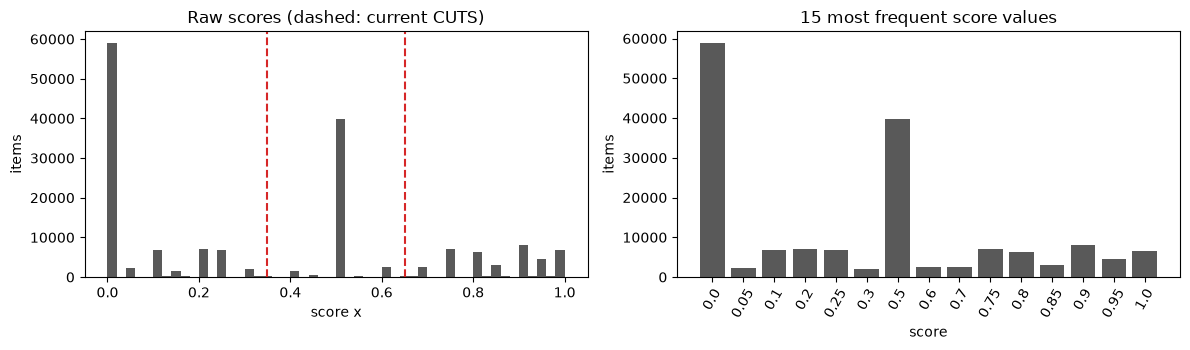

In [4]:
items = events.build_items(threads, submissions)
x = items["x"].dropna()
print(f"items: {len(items):,} | scored: {len(x):,} ({len(x) / len(items):.1%}) | NI: {items['x'].isna().sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(x, bins=50, color="0.35")
for c in cfg.CUTS:
    ax[0].axvline(c, color="C3", ls="--")
ax[0].set(title="Raw scores (dashed: current CUTS)", xlabel="score x", ylabel="items")
top = x.round(2).value_counts().head(15).sort_index()
ax[1].bar(top.index.astype(str), top.values, color="0.35")
ax[1].set(title="15 most frequent score values", xlabel="score", ylabel="items")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [5]:
cls = pd.Series(events.to_class(x, cfg.CUTS)).map(dict(enumerate(cfg.CLASS_LABELS)))
print("share of scored items per class with the current CUTS", cfg.CUTS)
print(cls.value_counts(normalize=True).reindex(cfg.CLASS_LABELS).round(3).to_string())
# how many items sit exactly on a cut or within 0.02 of it: these are the ones whose class is fragile
for c in cfg.CUTS:
    print(f"items within 0.02 of cut {c}: {((x - c).abs() <= 0.02).mean():.1%}")

share of scored items per class with the current CUTS (0.35, 0.65)
against    0.502
neutral    0.267
favour     0.231
items within 0.02 of cut 0.35: 0.3%
items within 0.02 of cut 0.65: 0.2%


## 3. Choose `VAR_CUT` from the histogram of group variances

For every reply we compute its group (the parent if scored and written by someone else, plus the earlier scored replies
to the same parent by other authors) and the mean and variance of the **raw** scores. These numbers do not depend on
`CUTS`, so this is safe to look at before choosing. This step builds the replies table, the own opinion `s`, and the
group statistics for the whole dataset; it can take a minute or two.

In [6]:
rep = events.build_replies(items)
rep = events.add_own_opinion(rep, items)
rep = events.add_group_stats(rep)
print(f"replies: {len(rep):,} | with a group of >= {cfg.MIN_MEMBERS} scored members: {(rep['g_n'] >= cfg.MIN_MEMBERS).sum():,}")
print("group size (scored members) for replies that have a group:")
print(rep.loc[rep["g_n"] >= 1, "g_n"].describe(percentiles=[.5, .9, .99]).round(1).to_string())

replies: 282,497 | with a group of >= 2 scored members: 67,563
group size (scored members) for replies that have a group:
count    135080.0
mean          8.0
std          20.5
min           1.0
50%           2.0
90%          19.0
99%         100.0
max         336.0


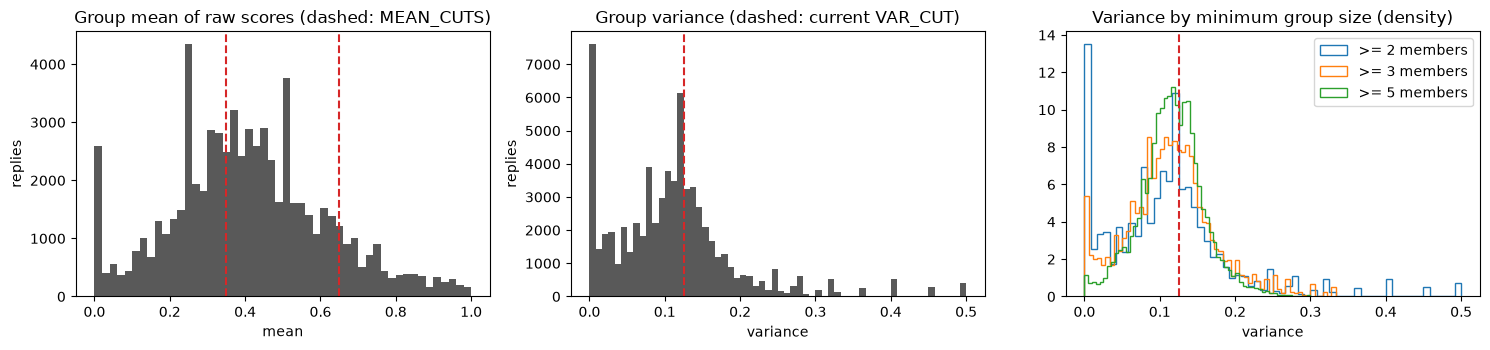

In [7]:
grp = rep[rep["g_n"] >= cfg.MIN_MEMBERS]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(grp["g_mu"], bins=50, color="0.35")
for c in cfg.MEAN_CUTS:
    ax[0].axvline(c, color="C3", ls="--")
ax[0].set(title="Group mean of raw scores (dashed: MEAN_CUTS)", xlabel="mean", ylabel="replies")
ax[1].hist(grp["g_var"], bins=60, color="0.35")
ax[1].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[1].set(title="Group variance (dashed: current VAR_CUT)", xlabel="variance", ylabel="replies")
for n_min, col in ((2, "C0"), (3, "C1"), (5, "C2")):
    ax[2].hist(rep.loc[rep["g_n"] >= n_min, "g_var"], bins=60, histtype="step", density=True, color=col, label=f">= {n_min} members")
ax[2].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[2].set(title="Variance by minimum group size (density)", xlabel="variance"); ax[2].legend()
plt.tight_layout(); plt.show()

In [8]:
# quantiles help to pick a cut: the bulk of 'consensus' groups should be clearly below it
kind = "unbiased sample variance" if cfg.VAR_UNBIASED else "population variance"
q = grp["g_var"].quantile([.1, .25, .5, .6, .7, .75, .8, .9]).round(4)
print(f"quantiles of the group {kind} (groups with >= MIN_MEMBERS members):")
print(q.to_string())
print("\nshare of groups called 'divided' for some candidate VAR_CUT values:")
cand = [0.02, 0.04, 0.06, 0.08, 0.10, 0.125, 0.15, 0.20, 0.25]
print(pd.Series({c: (grp["g_var"] >= c).mean() for c in cand}).round(3).to_string())
two = 2.0 if cfg.VAR_UNBIASED else 4.0     # 2 members: variance = (a - b)^2 / two
print(f"\nNote: with 2 members the variance is (a - b)^2 / {two:.0f}, so VAR_CUT = {cfg.VAR_CUT} means the two scores differ by > {(cfg.VAR_CUT * two) ** .5:.2f}.")

# the point of VAR_UNBIASED: the average variance should not depend on the group size
size = grp["g_n"].clip(upper=10).astype(int).rename("members (10 = 10 or more)")
by_size = pd.DataFrame({"groups": grp.groupby(size).size(),
                        "mean_var_pop": grp.groupby(size)["g_var_pop"].mean(),
                        "mean_var_used": grp.groupby(size)["g_var"].mean(),
                        "median_var_used": grp.groupby(size)["g_var"].median(),
                        "share_divided": grp.groupby(size)["g_var"].apply(lambda v: (v >= cfg.VAR_CUT).mean())}).round(4)
by_size

quantiles of the group unbiased sample variance (groups with >= MIN_MEMBERS members):
0.10    0.0050
0.25    0.0558
0.50    0.1074
0.60    0.1233
0.70    0.1340
0.75    0.1425
0.80    0.1532
0.90    0.2008

share of groups called 'divided' for some candidate VAR_CUT values:
0.020    0.860
0.040    0.800
0.060    0.741
0.080    0.665
0.100    0.550
0.125    0.390
0.150    0.215
0.200    0.102
0.250    0.058

Note: with 2 members the variance is (a - b)^2 / 2, so VAR_CUT = 0.125 means the two scores differ by > 0.50.


,groups,mean_var_pop,mean_var_used,median_var_used,share_divided
members (10 = 10 or more),,,,,
2,17807,0.0511,0.1022,0.0450,0.3585
3,8590,0.0725,0.1087,0.0833,0.3658
4,5383,0.0841,0.1121,0.1006,0.4221
5,3859,0.0916,0.1146,0.1145,0.4491
6,2970,0.0964,0.1157,0.1177,0.4559
7,2380,0.0989,0.1154,0.1154,0.4227
8,1970,0.1011,0.1156,0.1150,0.4279
9,1683,0.1024,0.1151,0.1157,0.4248
10,22921,0.1107,0.1162,0.1164,0.3882


## 4. Check that the 6 categories fill with the candidate cuts

This only counts how many groups land in each (own class × group category) cell, which is allowed before looking at
transitions. Change `CUTS`, `MEAN_CUTS` and `VAR_CUT` in `config.py` (and restart the kernel) if rows are nearly empty.

In [9]:
def category_fill(min_members):
    d = rep[(rep["g_n"] >= min_members) & rep[cfg.COL_S].notna()]
    mean_level = events.to_class(d["g_mu"], cfg.MEAN_CUTS)
    g = (2 * mean_level + (d["g_var"] >= cfg.VAR_CUT)).astype(int)
    tab = pd.crosstab(d[cfg.COL_S].astype(int), g).reindex(index=range(cfg.N_CLASSES), columns=range(cfg.N_G), fill_value=0)
    tab.index = [f"s={l}" for l in cfg.CLASS_LABELS]
    tab.columns = list(cfg.G_LABELS)
    return tab

for m in (2, 3):
    print(f"group events per (s, g) cell with >= {m} members (before date / gap filters):")
    display(category_fill(m))

group events per (s, g) cell with >= 2 members (before date / gap filters):


,lean-against-consensus,lean-against-divided,centre-consensus,centre-divided,lean-favour-consensus,lean-favour-divided
s=against,6058,2119,4864,5864,2127,391
s=neutral,2919,1010,2582,2961,1141,198
s=favour,2668,978,2346,2710,1117,217


group events per (s, g) cell with >= 3 members (before date / gap filters):


,lean-against-consensus,lean-against-divided,centre-consensus,centre-divided,lean-favour-consensus,lean-favour-divided
s=against,4571,1404,3841,4679,1076,269
s=neutral,2153,669,2016,2336,574,131
s=favour,1945,641,1852,2162,540,131


### Decision to record (end of Part A)

1. Write the chosen `CUTS` and `VAR_CUT` (and `MEAN_CUTS` if you change it) in `config.py`.
2. Set `CUTS_CHOSEN_FROM_HISTOGRAM = True` and `VAR_CUT_CHOSEN_FROM_HISTOGRAM = True` there, so the warnings disappear.
3. **Restart the kernel** so the new values are read, then continue with Part B (events and funnels).

Rule: cuts are fixed here and never revisited after seeing the tensors.

## B1. Composition representation: how many events per cell?

`events.build_events()` now returns a third table, `comp`, with the composition cell **c** and the mean x variance category **g**
on the same replies. The results in this notebook use **m = 3 classes only** (`against / neutral / favour`); the m = 2 code paths still exist but are not run here;
`COMP_MODE`, `COMP_MAX_SIZE`, `COMP_GRID` and `COMP_SIZE_EDGES` define the cells.
A row of the tensor is a pair (s, influencer); what matters is how many events each row holds, not the number of cells.

In [10]:
cfg.set_classes(3)                      # results are shown for m = 3 only
res = events.build_events(threads, submissions, verbose=False)
res["funnel_comp"]

,step,n,share_of_previous,share_of_comments
0,comments,282497,NaN,1.000
1,reply is scored (not NI),167274,0.592,0.592
2,author known,167274,1.000,0.592
3,parent present in the data,156532,0.936,0.554
4,reply within 2020-07-01 .. 2022-12-31,156517,1.000,0.554
5,replier has an earlier scored item (own opinio...,110131,0.704,0.390
6,group has >= 2 scored members,42268,0.384,0.150
7,group has at most 5 members -> composition e...,22128,0.524,0.078


### Fill of the three summaries side by side
`rows_below_t` = share of (s, influencer) rows with fewer than t events; `events_in_rows_below_t` = share of events that sit in such rows; `prior_weight` = share of the estimate that comes from the shrinkage prior; `cmi_bias_bits` = plug-in bias of the information measure.

In [11]:
events.compare_fill(res).T

summary,l parent class,g mean x variance,h mean x opposed pairs,g (comp events),h (comp events),c composition
influencer,l,g,h,g,h,c
categories,3,6,6,6,6,52
rows,9,18,18,18,18,156
rows_nonempty,9,18,18,18,18,154
events,87032,42268,42268,22128,22128,22128
median_R,8045.0,2236.0,2119.5,1176.5,1012.0,64.5
min_R_nonempty,5550,198,179,155,112,1
cells_sk_zero,0.0,0.0,0.0,0.0,0.0,0.025641
rows_below_10,0.0,0.0,0.0,0.0,0.0,0.076923
events_in_rows_below_10,0.0,0.0,0.0,0.0,0.0,0.00226


### Composition cells by group size

In [12]:
display(events.fill_by_size(res["comp"]).round(3))

,bin,sizes,cells,cells_observed,events,events_per_cell,rows_below_min,share_of_events
0,0,2,6,6,11279,626.611,0.111,0.510
1,1,3,10,10,5149,171.633,0.867,0.233
2,2,4,15,15,3330,74.000,1.000,0.150
3,3,5,21,21,2370,37.619,1.000,0.107


### The thinnest and the fullest rows (s, c)

,s,cell,s_label,label,R,n_k0,n_k1,n_k2,low
88,1,36,neutral,n=5: 0-5-0,0,0,0,0,True
140,2,36,favour,n=5: 0-5-0,0,0,0,0,True
36,0,36,against,n=5: 0-5-0,1,1,0,0,True
72,1,20,neutral,n=4: 0-4-0,3,2,1,0,True
139,2,35,favour,n=5: 0-4-1,3,1,2,0,True
87,1,35,neutral,n=5: 0-4-1,3,1,1,1,True
124,2,20,favour,n=4: 0-4-0,4,3,0,1,True
35,0,35,against,n=5: 0-4-1,6,2,0,4,True
135,2,31,favour,n=5: 0-0-5,6,2,1,3,True
145,2,41,favour,n=5: 1-4-0,8,4,2,2,True


,s,cell,s_label,label,R,n_k0,n_k1,n_k2,low
109,2,5,favour,n=2: 2-0-0,591,321,123,147,False
108,2,4,favour,n=2: 1-1-0,601,296,165,140,False
56,1,4,neutral,n=2: 1-1-0,622,299,181,142,False
55,1,3,neutral,n=2: 1-0-1,633,278,175,180,False
57,1,5,neutral,n=2: 2-0-0,639,352,169,118,False
0,0,0,against,n=2: 0-0-2,696,298,157,241,False
1,0,1,against,n=2: 0-1-1,796,358,218,220,False
3,0,3,against,n=2: 1-0-1,1199,627,287,285,False
4,0,4,against,n=2: 1-1-0,1206,632,335,239,False
5,0,5,against,n=2: 2-0-0,1263,748,311,204,False


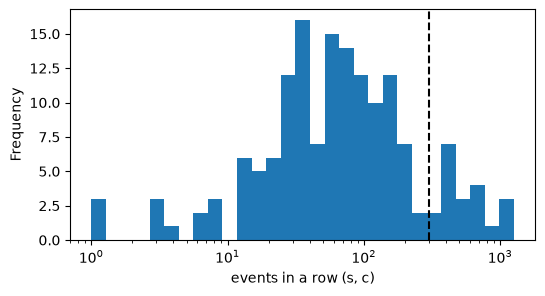

In [13]:
t = events.fill_table(res["comp"], cfg.COL_C)
display(t.sort_values("R").head(10)); display(t.sort_values("R").tail(10))
ax = t["R"].clip(lower=1).plot.hist(bins=np.logspace(0, np.log10(t["R"].max() + 1), 30), logx=True, figsize=(6, 3))
ax.axvline(cfg.MIN_ROW_EVENTS, color="k", ls="--"); ax.set_xlabel("events in a row (s, c)"); plt.show()

### Scan: which m and which cell definition keep the rows filled?

In [14]:
scan = events.scan_compositions(threads, submissions, ms=(3,), max_sizes=(3, 4, 5, 6), grids=(3, 4, 6))
scan.round(3)

,m,mode,option,categories,rows,events,median_R,min_R_nonempty,rows_below_300,events_in_rows_below_300,prior_weight,cmi_bias_bits
0,3,counts,n<=3,16,48,16428,214.5,30,0.583,0.249,0.116,0.004
1,3,counts,n<=4,31,93,19758,115.0,3,0.785,0.376,0.157,0.007
2,3,counts,n<=5,52,156,22128,64.5,1,0.872,0.443,0.194,0.010
3,3,counts,n<=6,80,240,23971,39.0,1,0.917,0.486,0.225,0.014
4,3,shares,grid 1/3,10,30,42268,1007.0,237,0.067,0.013,0.033,0.001
5,3,shares,grid 1/4,15,45,42268,724.0,119,0.200,0.045,0.049,0.001
6,3,shares,grid 1/6,28,84,42268,353.5,14,0.440,0.128,0.081,0.003


## B2. Which measure of the group captures its influence: unbiased variance or opposed pairs?

Every group has a **lean** (its mean level) and a **spread**. Two candidates for the spread coordinate, both unbiased in the group size:

* **variance**: the unbiased sample variance of the raw scores (`g = 2 * lean + variance level`);
* **opposed pairs**: `O` = share of pairs of members with one in the first and one in the last class, computed from the composition (`h = 2 * lean + opposition level`). `M` = share of mildly disagreeing pairs.

`OPP_CUT = None` in `config.py` chooses the cut of `O` that labels the same share of events 'high' as `VAR_CUT`, so the two summaries split the events in the same proportion. Both summaries have the same number of categories and are scored on the same events.

In [15]:
cfg.set_classes(3)      # m = 3 only (and polarization needs 3 classes: with 2 every disagreement counts as 'opposed')
res = events.build_events(threads, submissions, verbose=True)
grp_ev = res["group"]

OPP_CUT used: 0.263 (matched to VAR_CUT) | share of group events with high variance 0.389, with high opposition 0.389

=== funnel_dyadic ===
                                              step      n  share_of_previous  share_of_comments
                                          comments 282497                NaN              1.000
                          reply is scored (not NI) 167274              0.592              0.592
                                      author known 167274              1.000              0.592
                        parent present in the data 156532              0.936              0.554
             reply within 2020-07-01 .. 2022-12-31 156517              1.000              0.554
replier has an earlier scored item (own opinion s) 110131              0.704              0.390
                                  parent is scored  87887              0.798              0.311
               not a self-reply  ->  dyadic events  87032              0.990              0

### The two spread coordinates: distributions and their relation to group size

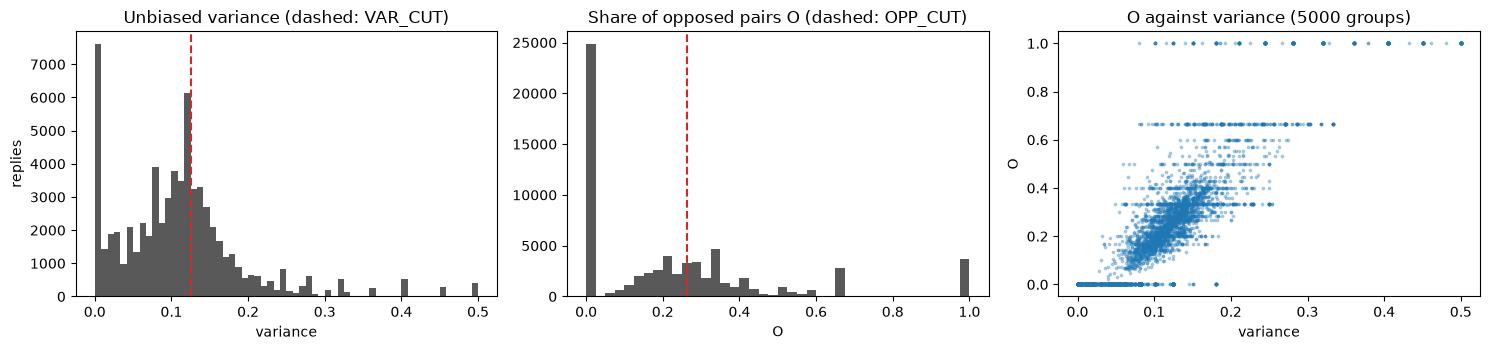

rank correlation variance vs O: 0.852


,groups,mean_O,mean_M,mean_var,share_high_var,share_high_O
members (10 = 10 or more),,,,,,
2,17807,0.209,0.363,0.102,0.359,0.209
3,8590,0.227,0.356,0.109,0.366,0.420
4,5383,0.236,0.355,0.112,0.422,0.495
5,3859,0.242,0.349,0.115,0.449,0.502
6,2970,0.243,0.353,0.116,0.456,0.538
7,2380,0.243,0.354,0.115,0.423,0.462
8,1970,0.244,0.354,0.116,0.428,0.449
9,1683,0.241,0.354,0.115,0.425,0.439
10,22921,0.242,0.354,0.116,0.388,0.421


In [16]:
rep_ = res["replies"]
elig = rep_[rep_["g_n"] >= cfg.MIN_MEMBERS]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(elig["g_var"], bins=60, color="0.35"); ax[0].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[0].set(title="Unbiased variance (dashed: VAR_CUT)", xlabel="variance", ylabel="replies")
ax[1].hist(elig["g_opp"].dropna(), bins=40, color="0.35"); ax[1].axvline(res["opp_cut"], color="C3", ls="--")
ax[1].set(title="Share of opposed pairs O (dashed: OPP_CUT)", xlabel="O")
ax[2].scatter(elig["g_var"].sample(min(len(elig), 5000), random_state=0), elig.loc[:, "g_opp"].sample(min(len(elig), 5000), random_state=0), s=3, alpha=.3)
ax[2].set(title="O against variance (5000 groups)", xlabel="variance", ylabel="O")
plt.tight_layout(); plt.show()
print("rank correlation variance vs O:", round(elig[["g_var", "g_opp"]].corr(method="spearman").iloc[0, 1], 3))

size = elig["g_n"].clip(upper=10).astype(int).rename("members (10 = 10 or more)")
display(pd.DataFrame({"groups": elig.groupby(size).size(),
                      "mean_O": elig.groupby(size)["g_opp"].mean(),
                      "mean_M": elig.groupby(size)["g_mild"].mean(),
                      "mean_var": elig.groupby(size)["g_var"].mean(),
                      "share_high_var": elig.groupby(size)["g_var"].apply(lambda v: (v >= cfg.VAR_CUT).mean()),
                      "share_high_O": elig.groupby(size)["g_opp"].apply(lambda v: (v >= res["opp_cut"]).mean())}).round(3))

Both columns `mean_O` and `mean_var` should be roughly flat in the group size if the unbiased versions work. How often the two summaries label a group the same way:

In [17]:
print("agreement of the 'high' labels (variance vs opposed pairs):")
display(pd.crosstab(grp_ev["var"] >= cfg.VAR_CUT, grp_ev["opp"] >= res["opp_cut"], normalize=True,
                    rownames=["high variance"], colnames=["high opposition"]).round(3))
display(events.compare_fill(res).T)

agreement of the 'high' labels (variance vs opposed pairs):


high opposition,False,True
high variance,,
False,0.534,0.077
True,0.077,0.312


summary,l parent class,g mean x variance,h mean x opposed pairs,g (comp events),h (comp events),c composition
influencer,l,g,h,g,h,c
categories,3,6,6,6,6,52
rows,9,18,18,18,18,156
rows_nonempty,9,18,18,18,18,154
events,87032,42268,42268,22128,22128,22128
median_R,8045.0,2236.0,2119.5,1176.5,1012.0,64.5
min_R_nonempty,5550,198,179,155,112,1
cells_sk_zero,0.0,0.0,0.0,0.0,0.0,0.025641
rows_below_10,0.0,0.0,0.0,0.0,0.0,0.076923
events_in_rows_below_10,0.0,0.0,0.0,0.0,0.0,0.00226


### The test: held-out log-loss of every summary on the same events

Bits per event, lower is better. `none` knows only the replier's own class. `size` is a **control**: the information carried by group size alone. `lean` is the mean level alone. `g` is lean + variance, `h` is lean + opposed pairs, `gh` uses both. `better_than_ref` is the gain over `g` in bits per event, with a user-bootstrap interval: **positive and an interval above 0 means that summary predicts better than the variance**.

In [18]:
cmp_group = tensors.compare_summaries(grp_ev)
print(f"{cmp_group['n_events']:,} events, {cmp_group['n_users']:,} users | reference summary: {cmp_group['ref']}")
cmp_group["table"].round(4)

42,268 events, 12,303 users | reference summary: g


,categories,logloss_bits,gain_vs_none,median_tau,better_than_ref,ref_lo,ref_hi
summary,,,,,,,
none,1,1.4977,0.0000,0.0,-0.0174,-0.0196,-0.0149
size,4,1.4972,0.0005,500.0,-0.0169,-0.0192,-0.0144
lean,3,1.4815,0.0163,50.0,-0.0011,-0.0018,-0.0004
lean_size,12,1.4817,0.0161,25.0,-0.0013,-0.0022,-0.0004
g,6,1.4804,0.0174,50.0,0.0000,0.0000,0.0000
h,6,1.4800,0.0177,50.0,0.0004,-0.0003,0.0011
gh,12,1.4800,0.0177,50.0,0.0003,-0.0003,0.0010
D(0),6,1.4800,0.0177,50.0,0.0004,-0.0003,0.0011
D(0.25),6,1.4801,0.0176,50.0,0.0003,-0.0004,0.0009


### Does one coordinate add information beyond the other?

Permutation test of I(K; coordinate | strata): the coordinate is shuffled among events that share the same strata. `cmi_excess` is what the coordinate adds beyond those strata, in bits per event. The size class is always among the strata, so a coordinate that is just a proxy for group size adds nothing here.

The last two rows ask the question about **mild pairs**: does `M` add anything once the opposed pairs are known, and the other way round?

In [19]:
cmp_group["added"].round(4)

,cmi_bits,null_mean,cmi_excess,p_value
coordinate | held fixed,,,,
"opposed pairs | s, lean, size",0.0017,0.0004,0.0013,0.0050
"variance | s, lean, size",0.0007,0.0002,0.0005,0.0050
"opposed pairs | s, lean, size, variance",0.0017,0.0009,0.0008,0.0050
"variance | s, lean, size, opposed pairs",0.0007,0.0007,0.0000,0.4129
"mild pairs | s, lean, size, opposed pairs",0.0021,0.0005,0.0016,0.0050
"opposed pairs | s, lean, size, mild pairs",0.0017,0.0009,0.0008,0.0050


### Are the mild pairs worth counting? The family D(w) = O + w·M

`w` is the weight of a mildly disagreeing pair relative to an opposed pair: **0** = opposed pairs only, **0.25** = variance of the class positions, **0.5** = mean absolute distance, **1** = every disagreeing pair counts the same. Each D(w) becomes a summary `lean level x high/low level` with the cut matched to the same share of 'high' events as `VAR_CUT`.

* `better_than_w0 > 0`: counting the mild pairs lowers the held-out loss.
* `better_than_ref` compares with `g` (variance of the **raw** scores): D(0.25) against `g` shows what the position of the scores inside each class adds.

In [20]:
cmp_group["family"].round(4)

,logloss_bits,gain_vs_none,better_than_ref,ref_lo,ref_hi,better_than_w0
w (weight of a mild pair),,,,,,
0.00,1.4800,0.0177,0.0004,-0.0003,0.0011,0.0000
0.25,1.4801,0.0176,0.0003,-0.0004,0.0009,-0.0001
0.50,1.4809,0.0168,-0.0005,-0.0012,0.0001,-0.0009
1.00,1.4813,0.0164,-0.0009,-0.0017,-0.0001,-0.0013


Repeat on the composition events (groups of at most `COMP_MAX_SIZE` members), which also contain the composition cell `c`:

In [21]:
cmp_comp = tensors.compare_summaries(res["comp"])
print(f"{cmp_comp['n_events']:,} events")
display(cmp_comp["table"].round(4)); display(cmp_comp["added"].round(4))

22,128 events


,categories,logloss_bits,gain_vs_none,median_tau,better_than_ref,ref_lo,ref_hi
summary,,,,,,,
none,1,1.5063,0.0000,0.0,-0.0171,-0.0211,-0.0139
size,4,1.5060,0.0003,500.0,-0.0168,-0.0208,-0.0134
lean,3,1.4900,0.0163,50.0,-0.0009,-0.0018,0.0001
lean_size,12,1.4905,0.0158,50.0,-0.0013,-0.0027,0.0000
g,6,1.4892,0.0171,50.0,0.0000,0.0000,0.0000
h,6,1.4885,0.0178,50.0,0.0007,-0.0002,0.0016
gh,12,1.4891,0.0172,50.0,0.0001,-0.0008,0.0008
D(0),6,1.4884,0.0179,50.0,0.0008,-0.0002,0.0016
D(0.25),6,1.4883,0.0180,50.0,0.0008,-0.0001,0.0017


,cmi_bits,null_mean,cmi_excess,p_value
coordinate | held fixed,,,,
"opposed pairs | s, lean, size",0.0014,0.0003,0.0011,0.0050
"variance | s, lean, size",0.0001,0.0002,-0.0000,0.5473
"opposed pairs | s, lean, size, variance",0.0014,0.0008,0.0006,0.0050
"variance | s, lean, size, opposed pairs",0.0001,0.0006,-0.0004,1.0000
"mild pairs | s, lean, size, opposed pairs",0.0015,0.0004,0.0012,0.0050
"opposed pairs | s, lean, size, mild pairs",0.0014,0.0005,0.0009,0.0050


### Robustness (change in `config.py`, restart the kernel, rerun B2)

* `MIN_MEMBERS = 3`: for 2 members `O` is only 0 or 1.
* `OPP_CUT` as a fixed number instead of the matched one.
* `CUTS` of the individual classes (the opposed pairs depend on them).
* Another `VAR_CUT` (the opposition cut follows it).

## B3. Does the group add to the dyad? (R4)

`events.py` now fills `l` (the parent's class) also in the group and composition events when the parent is scored and written by someone else, so the parent and the group are compared **on the same replies**. `coord` is the group coordinate to use: `g` (mean x variance) or `h` (mean x opposed pairs) — take the winner of B2.

* `table`: held-out log-loss of `none`, `size` (control), `l` (parent), the group coordinate, and `l+coord` (both). `better_than_ref` is the gain over the parent-only summary `l`, with a user-bootstrap interval.
* `added`: does the group add information once the parent is known (and the other way round)? The size class is always among the strata.

In [22]:
coord = cfg.COL_G            # or cfg.COL_H
bd = tensors.group_beyond_dyad(res["group"], coord=coord)
print(f"{bd['n_events']:,} events, {bd['n_users']:,} users | reference summary: {bd['ref']}")
display(bd["table"].round(4)); display(bd["added"].round(4))

38,685 events, 11,591 users | reference summary: l


,categories,logloss_bits,gain_vs_none,median_tau,better_than_ref,ref_lo,ref_hi
summary,,,,,,,
none,1,1.4995,0.0000,0.0,-0.0033,-0.0043,-0.0022
size,4,1.4991,0.0004,500.0,-0.0028,-0.0040,-0.0016
l,3,1.4962,0.0033,200.0,0.0000,0.0000,0.0000
g,6,1.4830,0.0165,50.0,0.0132,0.0110,0.0152
l+g,18,1.4829,0.0166,50.0,0.0133,0.0112,0.0153


,cmi_bits,null_mean,cmi_excess,p_value
coordinate | held fixed,,,,
"g | s, l, size",0.0177,0.0016,0.0161,0.0050
"l | s, g, size",0.0039,0.0036,0.0002,0.3184


## B4. How much of the new opinion is predictable, and from what? (R5)

Chain rule, in bits per event with the Miller-Madow bias correction:

`I(K; S, L, G) = I(K; S) + I(K; L | S) + I(K; G | S, L)`  = own opinion + the parent beyond it + the group beyond both.

`share_of_HK` is each term divided by H(K), the whole uncertainty about the new class. `excess` = estimate minus the mean of the permutation null (the influencer shuffled among events with the same earlier variables and the same size class); `p_value` is its permutation p-value. The interval is a user bootstrap centred on the estimate; for terms close to 0 trust `excess` and `p_value`.

In [23]:
# dyadic table: the larger sample, own opinion and parent only
dec_dyadic = tensors.information_decomposition(res["dyadic"], chain=[cfg.COL_S, cfg.COL_L])
print(f"dyadic: {dec_dyadic.attrs['n_events']:,} events")
display(dec_dyadic.round(4))

dyadic: 87,032 events


,bits,lo,hi,share_of_HK,null_mean,excess,p_value
H(K),1.5056,1.4986,1.5116,1.0000,NaN,NaN,NaN
I(K;S),0.0115,0.0099,0.0129,0.0076,NaN,NaN,NaN
I(K;L | S),0.0091,0.0078,0.0104,0.0061,0.0,0.0091,0.005
"I(K; S,L)",0.0206,0.0189,0.0225,0.0137,NaN,NaN,NaN


In [24]:
# group table: own opinion, parent, group (same replies for all terms)
dec_group = tensors.information_decomposition(res["group"], chain=[cfg.COL_S, cfg.COL_L, coord])
print(f"group: {dec_group.attrs['n_events']:,} events")
display(dec_group.round(4))

group: 38,685 events


,bits,lo,hi,share_of_HK,null_mean,excess,p_value
H(K),1.5060,1.4972,1.5140,1.0000,NaN,NaN,NaN
I(K;S),0.0067,0.0051,0.0087,0.0044,NaN,NaN,NaN
I(K;L | S),0.0036,0.0026,0.0048,0.0024,0.0000,0.0036,0.005
"I(K;G | S,L)",0.0150,0.0127,0.0174,0.0099,0.0002,0.0147,0.005
"I(K; S,L,G)",0.0253,0.0221,0.0288,0.0168,NaN,NaN,NaN


## Results for the slides (R1 to R5)
Everything below only **reads** objects made above (`res`, `cmp_group`, `bd`, `dec_dyadic`, `dec_group`, `coord`) and draws or prints the artifact for each result.
Run B1/B2/B3/B4 first. Figures are saved as PNG in `outputs/figures/`. The last cell checks that every artifact exists.

In [25]:
FIG = cfg.OUTPUTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
ARTIFACTS = {}                                   # name -> what was produced, filled by the cells below

for name in ("res", "cmp_group", "bd", "dec_dyadic", "dec_group", "coord"):
    assert name in globals(), f"'{name}' is missing: run B2 (res, cmp_group), B3 (bd, coord) and B4 (dec_*) first"
assert cfg.N_CLASSES == 3, 'results are shown for m = 3 only: run B1/B2 with cfg.set_classes(3)'
M = cfg.N_CLASSES
CL = list(cfg.CLASS_LABELS)

def save(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    ARTIFACTS[name] = path
    return path

### R1. Persistence: what a person does when nothing else is known
Each event is one reply; the tensor entries are conditional probabilities, so every row sums to 1. Funnel first, then p(k | s), the probability of keeping the class and H(K | S).

--- event funnel: dyadic


,step,n,share_of_previous,share_of_comments
0,comments,282497,NaN,1.000
1,reply is scored (not NI),167274,0.592,0.592
2,author known,167274,1.000,0.592
3,parent present in the data,156532,0.936,0.554
4,reply within 2020-07-01 .. 2022-12-31,156517,1.000,0.554
5,replier has an earlier scored item (own opinio...,110131,0.704,0.390
6,parent is scored,87887,0.798,0.311
7,not a self-reply -> dyadic events,87032,0.990,0.308


--- event funnel: group


,step,n,share_of_previous,share_of_comments
0,comments,282497,NaN,1.000
1,reply is scored (not NI),167274,0.592,0.592
2,author known,167274,1.000,0.592
3,parent present in the data,156532,0.936,0.554
4,reply within 2020-07-01 .. 2022-12-31,156517,1.000,0.554
5,replier has an earlier scored item (own opinio...,110131,0.704,0.390
6,group has >= 2 scored members -> group events,42268,0.384,0.150


--- event funnel: composition (preliminary)


,step,n,share_of_previous,share_of_comments
0,comments,282497,NaN,1.000
1,reply is scored (not NI),167274,0.592,0.592
2,author known,167274,1.000,0.592
3,parent present in the data,156532,0.936,0.554
4,reply within 2020-07-01 .. 2022-12-31,156517,1.000,0.554
5,replier has an earlier scored item (own opinio...,110131,0.704,0.390
6,group has >= 2 scored members,42268,0.384,0.150
7,group has at most 5 members -> composition e...,22128,0.524,0.078


,n_events,p(against),p(neutral),p(favour),stay,stay_lo,stay_hi
own class s,,,,,,,
against,43087,0.550,0.245,0.205,0.550,0.542,0.557
neutral,23179,0.452,0.306,0.241,0.306,0.299,0.314
favour,20766,0.421,0.270,0.308,0.308,0.300,0.319


H(K | S) = 1.494 bits  [1.488, 1.500]   (H(K) = 1.506 bits)


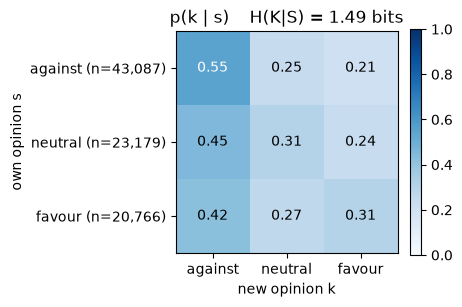

In [26]:
funnels = {"dyadic": res["funnel_dyadic"], "group": res["funnel_group"], "composition (preliminary)": res["funnel_comp"]}
for name, f in funnels.items():
    print(f"--- event funnel: {name}")
    display(f)
ARTIFACTS["R1_funnels"] = "printed"

ev1 = res["dyadic"]
ev1 = ev1[ev1[cfg.COL_S].notna() & ev1[cfg.COL_K].notna()]
s_ = ev1[cfg.COL_S].astype(int).to_numpy(); k_ = ev1[cfg.COL_K].astype(int).to_numpy()
Nsk = np.zeros((M, M)); np.add.at(Nsk, (s_, k_), 1)
Psk = Nsk / Nsk.sum(1, keepdims=True)
ps = Nsk.sum(1) / Nsk.sum()
Hks = float(-(ps * np.nansum(np.where(Psk > 0, Psk * np.log2(np.where(Psk > 0, Psk, 1)), 0), axis=1)).sum())

# user-level bootstrap of the stay probability and of H(K|S)
boots = tensors._boot_counts(ev1["user"].to_numpy(), s_ * M + k_, M * M, cfg.B, cfg.SEED).reshape(-1, M, M)
Pb = boots / boots.sum(-1, keepdims=True)
stay_b = np.stack([Pb[:, s, s] for s in range(M)], 1)
stay_lo, stay_hi = np.nanpercentile(stay_b, cfg.CI, axis=0)
pb_s = boots.sum(-1) / boots.sum((1, 2))[:, None]
with np.errstate(divide="ignore", invalid="ignore"):
    Hb = -(pb_s * np.nansum(np.where(Pb > 0, Pb * np.log2(np.where(Pb > 0, Pb, 1)), 0), axis=2)).sum(1)
H_lo, H_hi = np.nanpercentile(Hb, cfg.CI)

r1 = pd.DataFrame({"n_events": Nsk.sum(1).astype(int), **{f"p({c})": Psk[:, j] for j, c in enumerate(CL)},
                   "stay": np.diag(Psk), "stay_lo": stay_lo, "stay_hi": stay_hi}, index=pd.Index(CL, name="own class s"))
display(r1.round(3))
print(f"H(K | S) = {Hks:.3f} bits  [{H_lo:.3f}, {H_hi:.3f}]   (H(K) = {float(-(Nsk.sum(0)/Nsk.sum() * np.log2(Nsk.sum(0)/Nsk.sum())).sum()):.3f} bits)")

fig, ax = plt.subplots(figsize=(4.4, 3.6))
im = ax.imshow(Psk, cmap="Blues", vmin=0, vmax=1)
for i in range(M):
    for j in range(M):
        ax.text(j, i, f"{Psk[i, j]:.2f}", ha="center", va="center", color="white" if Psk[i, j] > .5 else "black")
ax.set_xticks(range(M)); ax.set_xticklabels(CL); ax.set_yticks(range(M)); ax.set_yticklabels([f"{c} (n={int(n):,})" for c, n in zip(CL, Nsk.sum(1))])
ax.set_xlabel("new opinion k"); ax.set_ylabel("own opinion s"); ax.set_title(f"p(k | s)    H(K|S) = {Hks:.2f} bits")
plt.colorbar(im, ax=ax, fraction=.046); plt.tight_layout()
save(fig, "R1_persistence"); plt.show()
ARTIFACTS["R1_table"] = "printed"

### R2. Dyadic influence: how much does the parent's class move the new opinion?
Heatmaps show only the **difference** p(k | s, l) − p(k | s), in percentage points: how much more (red) or less (blue) likely each new class is once the parent's class l is known, compared with everyone who has the same own class s. One panel per own class s; rows are the parent's class l; `*` marks cells whose user-bootstrap interval excludes 0. Raw proportions (no shrinkage).

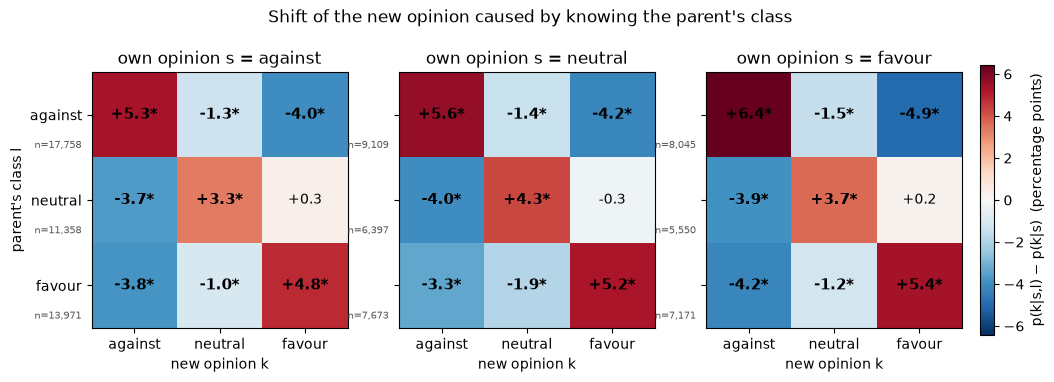

probability of moving toward the parent's class, when the parent's class differs from the own class


,s,l,n_events,flag,toward,toward_lo,toward_hi
1,against,neutral,11358,,0.487,0.469,0.504
2,against,favour,13971,,0.488,0.472,0.504
3,neutral,against,9109,,0.508,0.498,0.520
5,neutral,favour,7673,,0.293,0.282,0.305
6,favour,against,8045,,0.741,0.719,0.762
7,favour,neutral,5550,,0.689,0.664,0.715


I(K; L | S) = 0.0092 bits | excess over the thread-matched shuffle = 0.0058 | p = 0.0050  (shuffle within s and thread, 200 permutations; smallest possible p = 0.0050)


In [27]:
fit_l = tensors.fit_tensor(res["dyadic"], cfg.COL_L)
sh = tensors.shift_tensor(res["dyadic"], cfg.COL_L)
vmax = float(np.nanmax(np.abs(sh["shift"]))) * 100

fig, axes = plt.subplots(1, M, figsize=(3.9 * M, 3.5), sharey=True)
for s, ax in enumerate(np.atleast_1d(axes)):
    A = sh["shift"][s] * 100
    im = ax.imshow(A, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for l in range(M):
        for k in range(M):
            if np.isnan(A[l, k]):
                continue
            star = "*" if sh["sig"][s, l, k] else ""
            ax.text(k, l, f"{A[l, k]:+.1f}{star}", ha="center", va="center",
                    fontweight="bold" if star else "normal", fontsize=11 if star else 10)
    ax.set_xticks(range(M)); ax.set_xticklabels(CL)
    ax.set_title(f"own opinion s = {CL[s]}")
    ax.set_xlabel("new opinion k")
    if s == 0:
        ax.set_yticks(range(M)); ax.set_yticklabels([f"{CL[l]}" for l in range(M)]); ax.set_ylabel("parent's class l")
    for l in range(M):
        ax.text(-0.62, l + 0.36, f"n={int(sh['n'][s, l]):,}", ha="right", va="center", fontsize=7, color="0.35")
fig.colorbar(im, ax=axes, fraction=.02, pad=.02, label="p(k|s,l) − p(k|s)  (percentage points)")
fig.suptitle("Shift of the new opinion caused by knowing the parent's class", y=1.04)
save(fig, "R2_shift_heatmaps"); plt.show()
ARTIFACTS["R2_shift_table"] = sh["table"]

tw = fit_l["summary"]
tw = tw[tw["toward"].notna()][["s", cfg.COL_L, "n_events", "flag", "toward", "toward_lo", "toward_hi"]]
print("probability of moving toward the parent's class, when the parent's class differs from the own class")
display(tw.round(3))
ARTIFACTS["R2_toward_table"] = tw

pt, ps_ = fit_l["perm_s_thread"], fit_l["perm_s"]
print(f"I(K; L | S) = {pt['cmi']:.4f} bits | excess over the thread-matched shuffle = {pt['cmi_excess']:.4f} | "
      f"p = {pt['p_value']:.4f}  (shuffle within s and thread, {cfg.N_PERM} permutations; smallest possible p = {1/(cfg.N_PERM+1):.4f})")

#### Backup (only if asked): the shuffled-parent null
The parent's class is shuffled among events with the same own class (and, in the stricter version, the same thread). The histogram shows what I(K; L | S) looks like when the parent carries no information; the red line is the data.

,I(K;L|S) data (bits),null mean,null 95th pct,excess,p
shuffle within,,,,,
own class s,0.00922,0.00010,0.00017,0.00912,0.00498
own class s + thread,0.00922,0.00342,0.00391,0.00580,0.00498


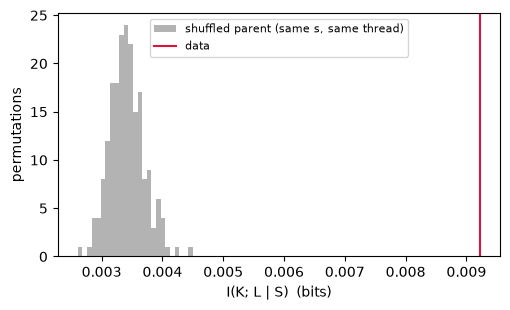

In [28]:
null_tbl = pd.DataFrame({
    "shuffle within": ["own class s", "own class s + thread"],
    "I(K;L|S) data (bits)": [ps_["cmi"], pt["cmi"]],
    "null mean": [np.mean(ps_["null"]), np.mean(pt["null"])],
    "null 95th pct": [np.percentile(ps_["null"], 95), np.percentile(pt["null"], 95)],
    "excess": [ps_["cmi_excess"], pt["cmi_excess"]],
    "p": [ps_["p_value"], pt["p_value"]]}).set_index("shuffle within")
display(null_tbl.round(5))
ARTIFACTS["R2_backup_null_table"] = null_tbl

fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.hist(pt["null"], bins=25, color="0.7", label="shuffled parent (same s, same thread)")
ax.axvline(pt["cmi"], color="crimson", label="data")
ax.set_xlabel("I(K; L | S)  (bits)"); ax.set_ylabel("permutations"); ax.legend(fontsize=8)
plt.tight_layout(); save(fig, "R2_backup_null_hist"); plt.show()

### R3. Which description of the group captures its influence?
Held-out log-loss of each group summary on the same events (user folds, shrinkage chosen inside training folds). The bars show the gain **relative to the reference summary** with a paired user-bootstrap interval; a bar whose interval stays above 0 is clearly better than the reference.

42,268 events, 12,303 users | reference: no group opinion (held-out log-loss 1.4977 bits per event)


,categories,logloss_bits,gain_vs_none,median_tau,gain_bits,gain_lo,gain_hi
summary,,,,,,,
No group opinion,1,1.4977,0.0000,0.0,0.0000,0.0000,0.0000
Group size only,4,1.4972,0.0005,500.0,0.0005,0.0000,0.0009
Mean group opinion,3,1.4815,0.0163,50.0,0.0163,0.0139,0.0185
Mean + size,12,1.4817,0.0161,25.0,0.0161,0.0137,0.0184
Mean + variance,6,1.4804,0.0174,50.0,0.0174,0.0149,0.0196
Mean + share of opposed pairs,6,1.4800,0.0177,50.0,0.0177,0.0153,0.0201
Mean + variance + share of opposed pairs,12,1.4800,0.0177,50.0,0.0177,0.0153,0.0199
D(0),6,1.4800,0.0177,50.0,0.0177,0.0153,0.0201
D(0.25),6,1.4801,0.0176,50.0,0.0176,0.0152,0.0201


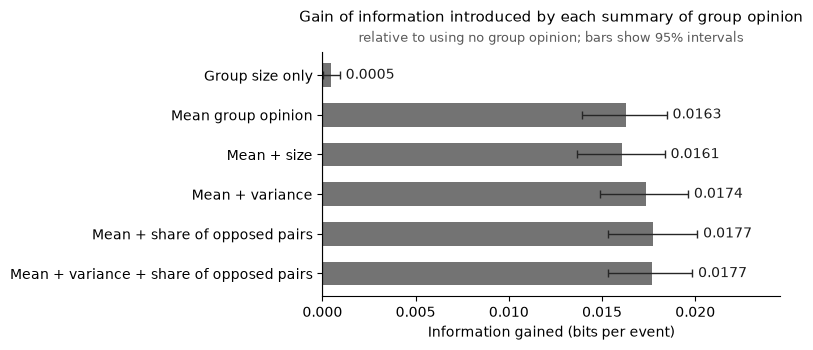

family D(w) = O + w·M  (w = weight of the mild pairs; w = 0 is the share of opposed pairs only)


,logloss_bits,gain_vs_none,gain_bits,gain_lo,gain_hi,better_than_w0
w (weight of a mild pair),,,,,,
0.00,1.4800,0.0177,0.0177,0.0153,0.0201,0.0000
0.25,1.4801,0.0176,0.0176,0.0152,0.0201,-0.0001
0.50,1.4809,0.0168,0.0168,0.0143,0.0190,-0.0009
1.00,1.4813,0.0164,0.0164,0.0141,0.0187,-0.0013


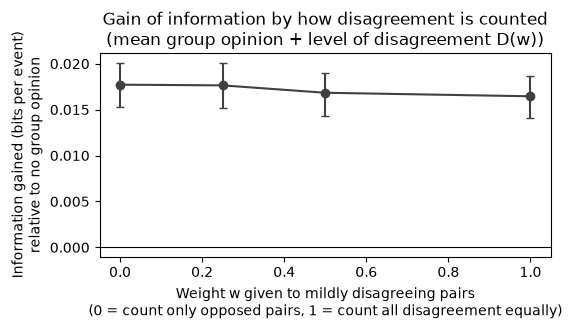

does one coordinate add information beyond the other? (permutation test of I(K; coordinate | S, other))


,cmi_bits,null_mean,cmi_excess,p_value
coordinate | held fixed,,,,
"opposed pairs | s, lean, size",0.0017,0.0004,0.0013,0.0050
"variance | s, lean, size",0.0007,0.0002,0.0005,0.0050
"opposed pairs | s, lean, size, variance",0.0017,0.0009,0.0008,0.0050
"variance | s, lean, size, opposed pairs",0.0007,0.0007,0.0000,0.4129
"mild pairs | s, lean, size, opposed pairs",0.0021,0.0005,0.0016,0.0050
"opposed pairs | s, lean, size, mild pairs",0.0017,0.0009,0.0008,0.0050


In [39]:
# every summary is compared with 'none' (no group information: the new opinion is predicted from the own opinion only),
# so each bar is the information gained by describing the group in that way
cmp0 = tensors.compare_summaries(res["group"], ref="none", tests=False)      # same events and folds as cmp_group
tb = cmp0["table"]
NAMES = {"none": "No group opinion", "size": "Group size only", "lean": "Mean group opinion",
         "lean_size": "Mean + size", "g": "Mean + variance", "h": "Mean + share of opposed pairs",
         "gh": "Mean + variance + share of opposed pairs"}
print(f"{cmp0['n_events']:,} events, {cmp0['n_users']:,} users | reference: no group opinion "
      f"(held-out log-loss {tb.loc['none', 'logloss_bits']:.4f} bits per event)")
tb_show = tb.rename(index=NAMES).rename(columns={"better_than_ref": "gain_bits", "ref_lo": "gain_lo", "ref_hi": "gain_hi"})
display(tb_show.round(4))
ARTIFACTS["R3_table"] = tb_show

show = [r for r in ("size", "lean", "lean_size", "g", "h", "gh") if r in tb.index]
d_ = tb.loc[show]
from matplotlib.ticker import MaxNLocator
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(d_))
ax.barh(y, d_["better_than_ref"], color="0.45", height=0.6,
        xerr=[d_["better_than_ref"] - d_["ref_lo"], d_["ref_hi"] - d_["better_than_ref"]],
        error_kw=dict(ecolor="0.15", lw=1, capsize=3))
for yi, v, hi in zip(y, d_["better_than_ref"], d_["ref_hi"]):          # value at the right of the interval
    ax.text(max(hi, v) + 0.015 * d_["ref_hi"].max(), yi, f"{v:.4f}", va="center", ha="left", fontsize=10, color="0.1")
ax.axvline(0, color="k", lw=.8)
ax.set_yticks(y); ax.set_yticklabels([NAMES[r] for r in d_.index]); ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.set_xlim(0, d_["ref_hi"].max() * 1.22)
ax.set_xlabel("Information gained (bits per event)")
ax.set_title("Gain of information introduced by each summary of group opinion", fontsize=11, pad=22)
ax.text(0.5, 1.03, "relative to using no group opinion; bars show 95% intervals", transform=ax.transAxes,
        ha="center", va="bottom", fontsize=9, color="0.35")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); save(fig, "R3_summaries"); plt.show()

fam = cmp0["family"]
print("family D(w) = O + w·M  (w = weight of the mild pairs; w = 0 is the share of opposed pairs only)")
display(fam.rename(columns={"better_than_ref": "gain_bits", "ref_lo": "gain_lo", "ref_hi": "gain_hi"}).round(4))
ARTIFACTS["R3_family_table"] = fam
fig, ax = plt.subplots(figsize=(5.8, 3.4))
w = np.asarray(fam.index, dtype=float)
ax.errorbar(w, fam["better_than_ref"], yerr=[fam["better_than_ref"] - fam["ref_lo"], fam["ref_hi"] - fam["better_than_ref"]],
            fmt="o-", color="0.25", capsize=3)
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("Weight w given to mildly disagreeing pairs\n(0 = count only opposed pairs, 1 = count all disagreement equally)")
ax.set_ylabel("Information gained (bits per event)\nrelative to no group opinion")
ax.set_title("Gain of information by how disagreement is counted\n(mean group opinion + level of disagreement D(w))")
plt.tight_layout(); save(fig, "R3_family"); plt.show()

print("does one coordinate add information beyond the other? (permutation test of I(K; coordinate | S, other))")
display(cmp_group["added"].round(4))
ARTIFACTS["R3_added_table"] = cmp_group["added"]

### R4. Does the group add to the dyad?
Reference summary: the parent's class l. Bars: gain in held-out log-loss of adding the group coordinate (and of the group alone) relative to l, with a paired interval. Table below: permutation tests of the conditional information.

38,685 events, 11,591 users | reference: parent opinion only (summary 'l') | group coordinate: g


,categories,logloss_bits,gain_vs_none,median_tau,gain_bits,gain_lo,gain_hi
summary,,,,,,,
Neither parent nor group,1,1.4995,0.0000,0.0,-0.0033,-0.0043,-0.0022
Group size only,4,1.4991,0.0004,500.0,-0.0028,-0.0040,-0.0016
Parent opinion only,3,1.4962,0.0033,200.0,0.0000,0.0000,0.0000
Group (mean + variance) only,6,1.4830,0.0165,50.0,0.0132,0.0110,0.0152
Parent opinion + group (mean + variance),18,1.4829,0.0166,50.0,0.0133,0.0112,0.0153


,cmi_bits,null_mean,cmi_excess,p_value
coordinate | held fixed,,,,
"g | s, l, size",0.0177,0.0016,0.0161,0.0050
"l | s, g, size",0.0039,0.0036,0.0002,0.3184


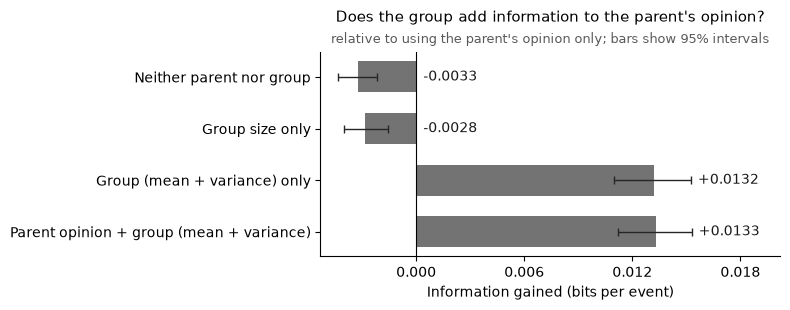

In [32]:
tb4 = bd["table"]
print(f"{bd['n_events']:,} events, {bd['n_users']:,} users | reference: parent opinion only (summary '{bd['ref']}') | group coordinate: {coord}")

# readable labels for the rows (the group coordinate is g = mean + variance, or h = mean + share of opposed pairs)
GROUP = {"g": "mean + variance", "h": "mean + share of opposed pairs"}.get(coord, coord)
NAMES4 = {"none": "Neither parent nor group", "size": "Group size only", coord: f"Group ({GROUP}) only",
          f"{cfg.COL_L}+{coord}": f"Parent opinion + group ({GROUP})", cfg.COL_L: "Parent opinion only"}
tb4_show = tb4.rename(index=NAMES4).rename(columns={"better_than_ref": "gain_bits", "ref_lo": "gain_lo", "ref_hi": "gain_hi"})
display(tb4_show.round(4)); display(bd["added"].round(4))
ARTIFACTS["R4_table"] = tb4_show; ARTIFACTS["R4_added_table"] = bd["added"]

from matplotlib.ticker import MaxNLocator
d4 = tb4.drop(index=[bd["ref"]])
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(d4))
ax.barh(y, d4["better_than_ref"], color="0.45", height=0.6,
        xerr=[d4["better_than_ref"] - d4["ref_lo"], d4["ref_hi"] - d4["better_than_ref"]],
        error_kw=dict(ecolor="0.15", lw=1, capsize=3))
span = d4["ref_hi"].max() - d4["ref_lo"].min()
for yi, v, hi in zip(y, d4["better_than_ref"], d4["ref_hi"]):           # value to the right of the interval (or of 0)
    ax.text(max(hi, 0) + 0.02 * span, yi, f"{v:+.4f}", va="center", ha="left", fontsize=10, color="0.1")
ax.axvline(0, color="k", lw=.8)
ax.set_yticks(y); ax.set_yticklabels([NAMES4[r] for r in d4.index]); ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.set_xlim(min(d4["ref_lo"].min(), 0) - 0.05 * span, d4["ref_hi"].max() + 0.25 * span)
ax.set_xlabel("Information gained (bits per event)")
ax.set_title("Does the group add information to the parent's opinion?", fontsize=11, pad=22)
ax.text(0.5, 1.03, "relative to using the parent's opinion only; bars show 95% intervals", transform=ax.transAxes,
        ha="center", va="bottom", fontsize=9, color="0.35")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); save(fig, "R4_group_vs_dyad"); plt.show()

### R5. How much of the new opinion is predictable, and from what?
Chain rule in bits per event: I(K; S) + I(K; L | S) + I(K; G | S, L). Bias-corrected (Miller-Madow); intervals are centred on the estimate; p-values from permutations.

dyadic sample: 87,032 events | group sample: 38,685 replies with own opinion, influencer and group
dyadic sample:


,bits,lo,hi,share_of_HK,null_mean,excess,p_value
H(K),1.5056,1.4986,1.5116,1.0000,NaN,NaN,NaN
I(K;S),0.0115,0.0099,0.0129,0.0076,NaN,NaN,NaN
I(K;L | S),0.0091,0.0078,0.0104,0.0061,0.0,0.0091,0.005
"I(K; S,L)",0.0206,0.0189,0.0225,0.0137,NaN,NaN,NaN


group sample, influencer:


,bits,lo,hi,share_of_HK,null_mean,excess,p_value
H(K),1.5060,1.4972,1.5140,1.0000,NaN,NaN,NaN
I(K;S),0.0067,0.0051,0.0087,0.0044,NaN,NaN,NaN
I(K;L | S),0.0036,0.0026,0.0048,0.0024,0.0,0.0036,0.005
"I(K; S,L)",0.0103,0.0082,0.0127,0.0069,NaN,NaN,NaN


group sample, group:


,bits,lo,hi,share_of_HK,null_mean,excess,p_value
H(K),1.5060,1.4972,1.5140,1.0000,NaN,NaN,NaN
I(K;S),0.0067,0.0051,0.0087,0.0044,NaN,NaN,NaN
I(K;G | S),0.0172,0.0147,0.0199,0.0114,0.0,0.0171,0.005
"I(K; S,G)",0.0239,0.0208,0.0272,0.0159,NaN,NaN,NaN


/tmp/ipykernel_7048/1189882831.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); fig.subplots_adjust(top=0.80, wspace=0.08); save(fig, "R5_information"); plt.show()


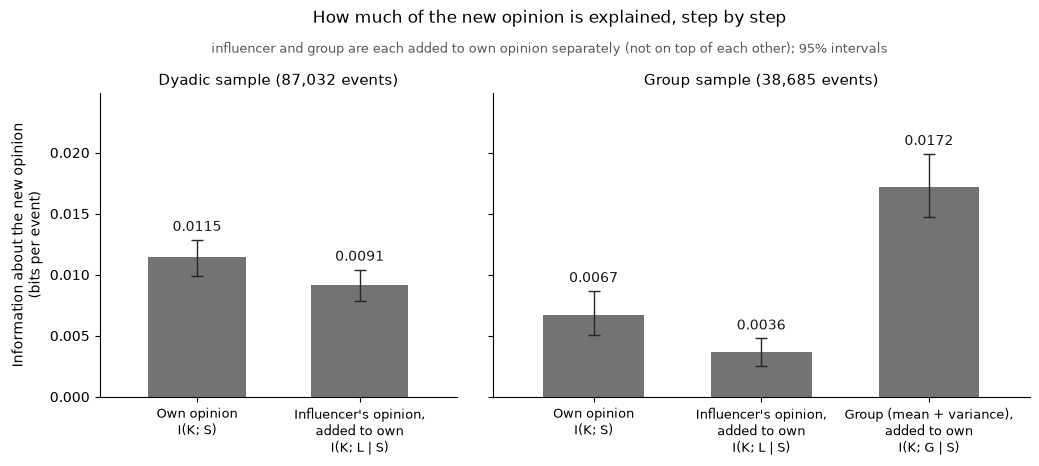

In [37]:
# Left: own + influencer on the full dyadic sample.  Right: the same plus the group, on the (fewer) events that have a group.
need = [cfg.COL_S, cfg.COL_L, coord, cfg.COL_K]
common = res["group"].dropna(subset=need).copy()
print(f"dyadic sample: {dec_dyadic.attrs.get('n_events', 0):,} events | group sample: {len(common):,} replies with own opinion, influencer and group")

dec_l = tensors.information_decomposition(common, chain=[cfg.COL_S, cfg.COL_L])          # I(K;S), I(K;L | S)
dec_g = tensors.information_decomposition(common, chain=[cfg.COL_S, coord])             # I(K;S), I(K;G | S)
print("dyadic sample:"); display(dec_dyadic.round(4))
print("group sample, influencer:"); display(dec_l.round(4))
print("group sample, group:"); display(dec_g.round(4))
ARTIFACTS["R5_dyadic_table"] = dec_dyadic; ARTIFACTS["R5_group_table"] = dec_g

GROUP = {"g": "mean + variance", "h": "mean + share of opposed pairs"}.get(coord, coord)
S_LBL = "Own opinion\nI(K; S)"
L_LBL = "Influencer's opinion,\nadded to own\nI(K; L | S)"
G_LBL = f"Group ({GROUP}),\nadded to own\nI(K; G | S)"
panels = [
    (f"Dyadic sample ({dec_dyadic.attrs.get('n_events', 0):,} events)", pd.DataFrame([dec_dyadic.iloc[1], dec_dyadic.iloc[2]]), [S_LBL, L_LBL]),
    (f"Group sample ({len(common):,} events)", pd.DataFrame([dec_g.iloc[1], dec_l.iloc[2], dec_g.iloc[2]]), [S_LBL, L_LBL, G_LBL]),
]
pmin = 1 / (cfg.N_PERM + 1)
top = max(t["hi"].max() for _, t, _ in panels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, gridspec_kw=dict(width_ratios=[2, 3], wspace=0.08))
for ax, (title, terms, labels) in zip(axes, panels):
    x = np.arange(len(terms))
    ax.bar(x, terms["bits"], color="0.45", width=0.6,
           yerr=[terms["bits"] - terms["lo"], terms["hi"] - terms["bits"]], error_kw=dict(ecolor="0.15", lw=1, capsize=4))
    for i, (b, hi, pv) in enumerate(zip(terms["bits"], terms["hi"], terms["p_value"])):
        note = f"{b:.4f}" + ("" if pv != pv or pv <= pmin + 1e-9 else f"\np = {pv:.3f}")
        ax.text(i, hi + 0.02 * top, note, ha="center", va="bottom", fontsize=10, color="0.1", linespacing=1.3)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
    ax.set_xlim(-0.6, len(terms) - 0.4)
    ax.set_ylim(0, top * 1.25)
    ax.set_title(title, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Information about the new opinion\n(bits per event)")
fig.suptitle("How much of the new opinion is explained, step by step", fontsize=12.5, y=0.99, va="top")
fig.text(0.5, 0.885, "influencer and group are each added to own opinion separately (not on top of each other); 95% intervals",
         ha="center", va="bottom", fontsize=9, color="0.35")
plt.tight_layout(); fig.subplots_adjust(top=0.80, wspace=0.08); save(fig, "R5_information"); plt.show()

### Final group transition tensor
The same reading as the dyadic heatmap in R2, now with the group summary chosen in R3/R4 (`coord`) in the rows: for each own opinion s (one panel), how much more (red) or less (blue) likely each new opinion k is for each kind of group, compared with everyone who has the same own opinion. Bold = the bootstrap interval excludes 0. Set `MODE = "prob"` to draw the probabilities p(k | s, group) themselves. Rows marked † have few events and should be read with care.

42,268 group events, group summary: h (6 categories), rows with fewer than 300 events are marked †


,s,h,k,n_row,p,baseline,shift,lo,hi,excludes_0
0,against,lean-against-low-opposition,against,6526,0.6102,0.5368,0.0734,0.0624,0.0844,True
1,against,lean-against-low-opposition,neutral,6526,0.2262,0.2319,-0.0057,-0.0138,0.0028,False
2,against,lean-against-low-opposition,favour,6526,0.1637,0.2313,-0.0677,-0.0765,-0.0595,True
3,against,lean-against-high-opposition,against,1651,0.6118,0.5368,0.0750,0.0486,0.0965,True
4,against,lean-against-high-opposition,neutral,1651,0.1962,0.2319,-0.0357,-0.0523,-0.0161,True
5,against,lean-against-high-opposition,favour,1651,0.1920,0.2313,-0.0393,-0.0569,-0.0186,True
6,against,centre-low-opposition,against,4379,0.4880,0.5368,-0.0488,-0.0618,-0.0368,True
7,against,centre-low-opposition,neutral,4379,0.2647,0.2319,0.0328,0.0210,0.0434,True
8,against,centre-low-opposition,favour,4379,0.2473,0.2313,0.0160,0.0041,0.0277,True
9,against,centre-high-opposition,against,6348,0.5211,0.5368,-0.0157,-0.0263,-0.0052,True


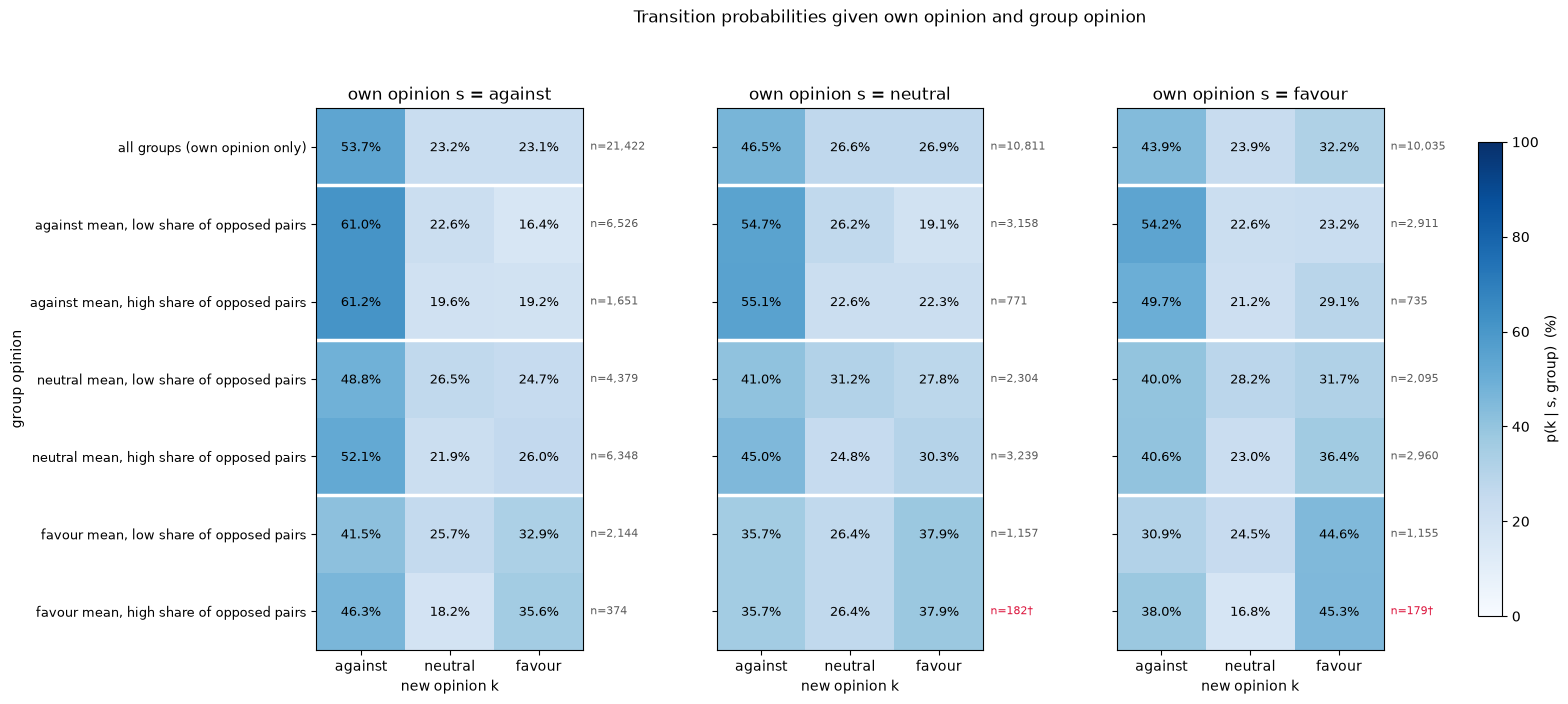

In [32]:
# Final group transition tensor: new opinion k given own opinion s and the group summary
GROUP_COORD = cfg.COL_H     # cfg.COL_G = mean + variance | cfg.COL_H = mean + share of opposed pairs (default: the one chosen above)
MODE = "shift"            # "both": probability in each cell, colour = shift p(k|s,group) - p(k|s)  |  "prob": probabilities only (blue scale)

gt = tensors.shift_tensor(res["group"], GROUP_COORD)
n_rows = gt["n"]                                           # events per (own opinion s, group category)
DISP = {"g": ("low variance", "high variance"),
        "h": ("low share of opposed pairs", "high share of opposed pairs")}.get(GROUP_COORD, ("low", "high"))
ROWS = ["all groups (own opinion only)"] + [f"{CL[i // 2]} mean, {DISP[i % 2]}" for i in range(n_rows.shape[1])]
print(f"{int(n_rows.sum()):,} group events, group summary: {GROUP_COORD} ({len(ROWS) - 1} categories), "
      f"rows with fewer than {cfg.MIN_ROW_EVENTS} events are marked †")
display(gt["table"].round(4))
ARTIFACTS["R_group_tensor_table"] = gt["table"]

P, S, base = gt["p"] * 100, gt["shift"] * 100, gt["q"] * 100          # P[s, i, k], S[s, i, k], base[s, k] = p(k | s)
nG = P.shape[1]
if MODE == "both":
    cmap = "RdBu_r"; vmax = float(np.nanmax(np.abs(S))); vmin = -vmax
    cbar_label = "colour: p(k|s,group) − p(k|s)  (percentage points)"
    title = "Transition probabilities p(k | s, group); colour shows the shift caused by the group"
else:
    cmap = "Blues"; vmin, vmax = 0.0, 100.0
    cbar_label = "p(k | s, group)  (%)"
    title = "Transition probabilities given own opinion and group opinion"

fig, axes = plt.subplots(1, M, figsize=(4.6 * M + 1.5, 0.72 * (nG + 1) + 2.0), sharey=True, gridspec_kw=dict(wspace=0.5))
for s, ax in enumerate(np.atleast_1d(axes)):
    text = np.vstack([base[s], P[s]])                                  # probabilities written in the cells
    color = np.vstack([np.zeros(M), S[s]]) if MODE == "both" else text # colour of the cells
    im = ax.imshow(color, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(nG + 1):
        for k in range(M):
            if np.isnan(text[i, k]):
                continue
            r, g_, b, _ = im.cmap(im.norm(color[i, k]))
            txt = "white" if 0.299 * r + 0.587 * g_ + 0.114 * b < 0.5 else "black"
            label = f"{text[i, k]:.1f}%"
            if MODE == "both" and i > 0:
                label += f"\n({S[s, i - 1, k]:+.1f})"
            bold = i > 0 and bool(gt["sig"][s, i - 1, k]) and MODE == "both"
            ax.text(k, i, label, ha="center", va="center", color=txt, fontsize=9.5, linespacing=1.15,
                    fontweight="bold" if bold else "normal")
        n_i = int(n_rows[s].sum()) if i == 0 else int(n_rows[s, i - 1])
        thin = i > 0 and n_i < cfg.MIN_ROW_EVENTS
        ax.text(M - 0.42, i, f"n={n_i:,}{'†' if thin else ''}", ha="left", va="center", fontsize=8,
                color="crimson" if thin else "0.35", clip_on=False)
    for edge in (0.5, 2.5, 4.5):                                       # baseline row | the three mean levels
        ax.axhline(edge, color="white", lw=2.5)
    ax.set_xticks(range(M)); ax.set_xticklabels(CL)
    ax.set_title(f"own opinion s = {CL[s]}")
    ax.set_xlabel("new opinion k")
    if s == 0:
        ax.set_yticks(range(nG + 1)); ax.set_yticklabels(ROWS, fontsize=9); ax.set_ylabel("group opinion")
fig.colorbar(im, ax=axes, fraction=.02, pad=.08, label=cbar_label)
fig.suptitle(title, y=1.02)
if MODE == "both":
    fig.text(0.5, -0.02, "cell: probability in %, shift in percentage points in brackets; bold = interval of the shift excludes 0; "
             "first row: probabilities knowing only the own opinion", ha="center", fontsize=9, color="0.35")
save(fig, "R_group_tensor_heatmap"); plt.show()

### Checklist: every result artifact

In [ ]:
expected = {
    "R1": ["R1_funnels", "R1_table", "R1_persistence"],
    "R2": ["R2_shift_heatmaps", "R2_shift_table", "R2_toward_table", "R2_backup_null_table", "R2_backup_null_hist"],
    "R3": ["R3_table", "R3_summaries", "R3_family_table", "R3_family", "R3_added_table"],
    "R4": ["R4_table", "R4_added_table", "R4_group_vs_dyad"],
    "R5": ["R5_dyadic_table", "R5_group_table", "R5_information"],
    "Group tensor": ["R_group_tensor_table", "R_group_tensor_heatmap"],
}
rows = []
for r, names in expected.items():
    for n in names:
        a = ARTIFACTS.get(n)
        ok = a is not None and (not hasattr(a, "exists") or a.exists())
        rows.append({"result": r, "artifact": n, "produced": ok, "where": str(a) if hasattr(a, "exists") else ("printed" if ok else "")})
chk = pd.DataFrame(rows)
display(chk)
assert chk["produced"].all(), "some artifacts were not produced: " + ", ".join(chk.loc[~chk["produced"], "artifact"])
print("all R1-R5 artifacts produced; figures in", FIG)

,result,artifact,produced,where
0,R1,R1_funnels,True,printed
1,R1,R1_table,True,printed
2,R1,R1_persistence,True,/home/guial/projects/empirical-opinion-dynamic...
3,R2,R2_shift_heatmaps,True,/home/guial/projects/empirical-opinion-dynamic...
4,R2,R2_shift_table,True,printed
5,R2,R2_toward_table,True,printed
6,R2,R2_backup_null_table,True,printed
7,R2,R2_backup_null_hist,True,/home/guial/projects/empirical-opinion-dynamic...
8,R3,R3_table,True,printed
9,R3,R3_summaries,True,/home/guial/projects/empirical-opinion-dynamic...


all R1-R5 artifacts produced; figures in /home/guial/projects/empirical-opinion-dynamics/reddit_climate/outputs/figures
